In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt

# DOANH THU, SỐ CHƯƠNG TRÌNH KHUYẾN MÃI VÀ TỔNG LƯỢNG ĐƠN HÀNG QUA CÁC MỐC THỜI GIAN

# Lợi nhuận thu được

In [4]:
dfSale =  pd.read_csv("Analytical/sales.csv")
dfSale.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3833 entries, 0 to 3832
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Date     3833 non-null   object 
 1   Revenue  3833 non-null   float64
 2   COGS     3833 non-null   float64
dtypes: float64(2), object(1)
memory usage: 90.0+ KB


In [5]:
dfSale["Date"] = pd.to_datetime(dfSale["Date"])
dfSale["Profit"] = dfSale["Revenue"] - dfSale["COGS"]
dfSale["yearMonth"] = dfSale["Date"].dt.strftime("%Y-%m")
dfSale["year"] = dfSale["Date"].dt.year
dfSale["month"] = dfSale["Date"].dt.month
dfSale.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3833 entries, 0 to 3832
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   Date       3833 non-null   datetime64[ns]
 1   Revenue    3833 non-null   float64       
 2   COGS       3833 non-null   float64       
 3   Profit     3833 non-null   float64       
 4   yearMonth  3833 non-null   object        
 5   year       3833 non-null   int32         
 6   month      3833 non-null   int32         
dtypes: datetime64[ns](1), float64(3), int32(2), object(1)
memory usage: 179.8+ KB


In [6]:
profitbyYear = dfSale.groupby("year")["Profit"].sum().reset_index().sort_values(by = "year")
profitbyYear

,year,Profit
0,2012,1.540358e+08
1,2013,1.911893e+08
2,2014,2.972384e+08
3,2015,2.244920e+08
4,2016,3.240813e+08
5,2017,2.167785e+08
6,2018,3.079467e+08
7,2019,1.315986e+08
8,2020,1.684271e+08
9,2021,1.019097e+08


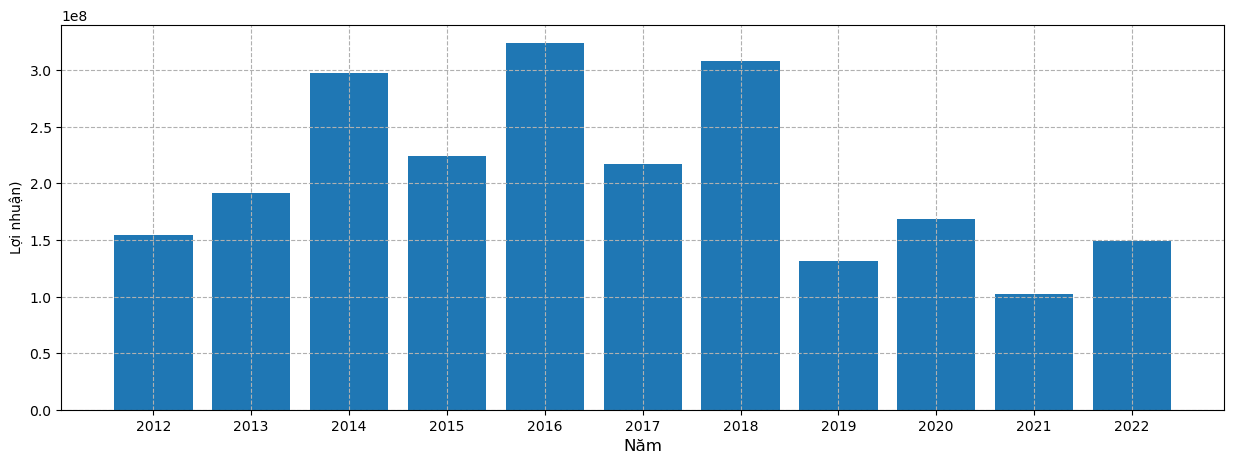

In [7]:
# profitbyYear = dfSale.groupby("year")["Profit"].sum()
# year = dfSale[]
pig, ax =  plt.subplots(figsize=(15, 5))
ax.bar(
    profitbyYear['year'],
    profitbyYear['Profit']
)
ax.set_ylabel('Lợi nhuận)')
ax.set_xlabel('Năm', fontsize=12)
ax.grid(ls = "--")
ax.set_xticks(range(min(profitbyYear['year']),max(profitbyYear['year'])+1))
plt.show()

In [8]:
dfSales = dfSale.groupby(["year","month"])["Profit"].sum().reset_index()
pd.pivot_table(dfSales, values='Profit', index=['year'], columns=['month'], aggfunc='sum').fillna(0)

month,1,2,3,4,5,6,7,8,9,10,11,12
year,,,,,,,,,,,,
2012,0.00,0.00,0.00,0.00,0.00,0.00,27890299.64,33503933.88,26710979.00,22130889.42,20366217.83,23433504.44
2013,18284872.95,19496261.35,21936874.84,33344970.79,40740955.68,32215066.82,12700740.10,-35675935.04,11372808.15,22404022.37,13253081.04,1115595.02
2014,16986788.57,22177009.93,26343257.52,35683116.99,49115634.24,34025677.09,17907887.60,40306261.09,15449416.13,24700925.28,12606496.89,1935954.58
2015,17952893.84,21612046.69,25969835.62,42031250.76,49244619.80,37635921.47,15478150.22,-38771622.48,14776485.32,26783285.02,11512778.13,266365.11
2016,21042750.78,24908838.02,24971552.81,39862417.97,52882578.42,40653936.88,18672139.18,45098760.96,16096444.61,25272200.19,13709868.41,909796.62
2017,18083934.17,19450129.24,25348806.73,34335137.34,51840649.98,42167185.21,14584363.00,-41512111.25,11132022.14,27062371.52,13372563.73,913479.93
2018,16441165.75,22508725.32,25990920.98,37131073.53,54184728.46,45327968.14,19064081.70,40438843.88,14704429.05,20688161.46,10083658.23,1382933.44
2019,14426215.81,16015604.76,17409817.40,21304983.58,29649972.31,22457285.88,7570977.10,-27900349.02,8226720.54,14269577.28,7508081.81,659670.34
2020,9738344.15,12629296.83,16414720.80,22169449.40,27254495.14,18087530.30,9387999.63,24023679.29,8788252.09,13737936.48,5760135.98,435221.07


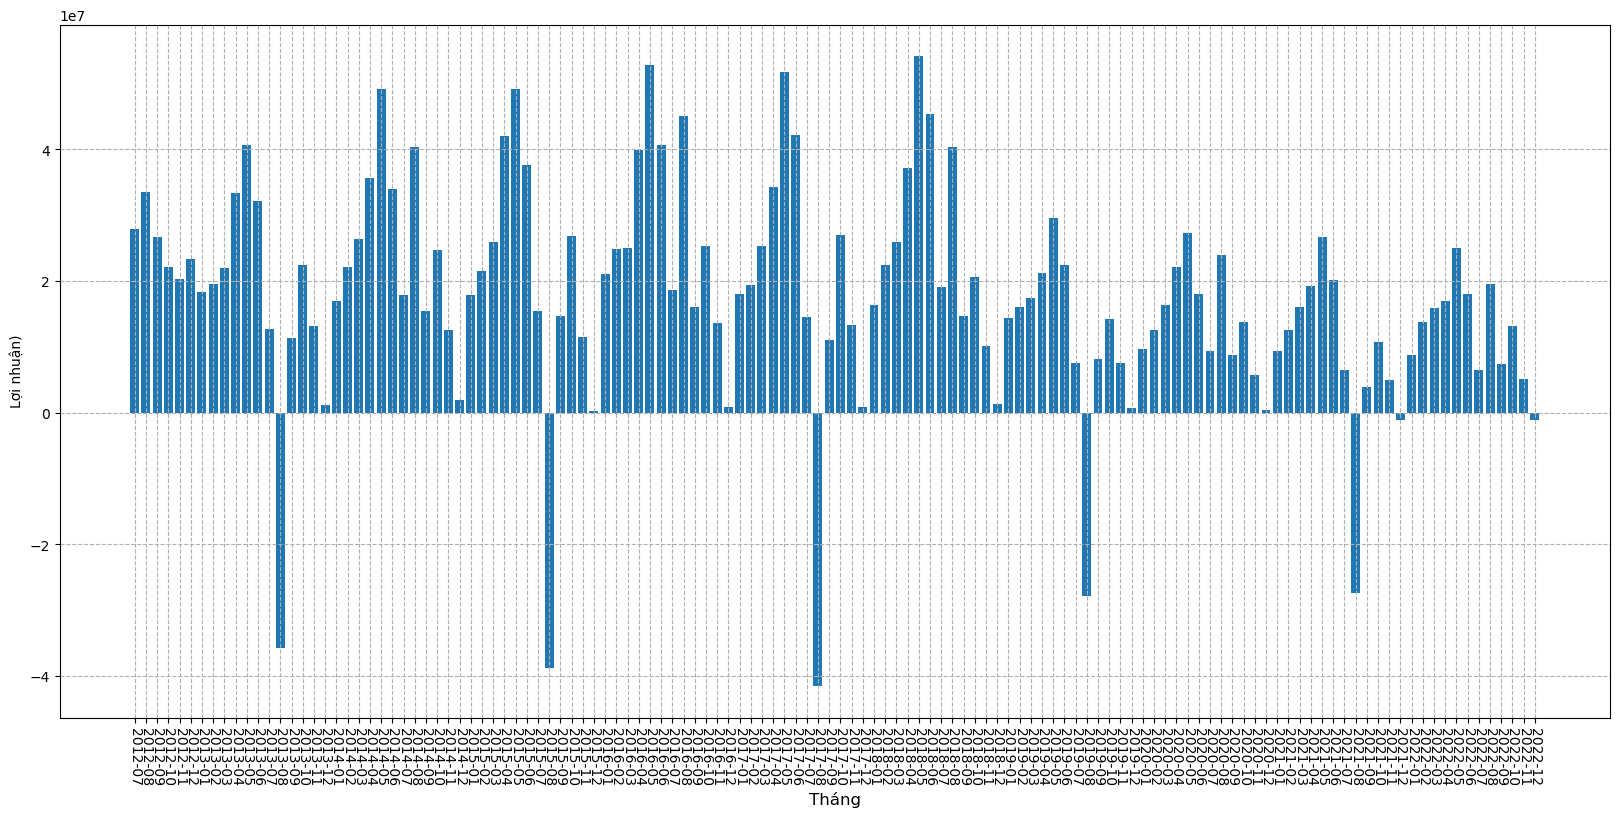

In [9]:
profitbyyearMonth = dfSale.groupby("yearMonth")["Profit"].sum()
pig, ax =  plt.subplots(figsize=(20, 9))
ax.bar(
    profitbyyearMonth.index,
    profitbyyearMonth.values
)
ax.set_ylabel('Lợi nhuận)')
ax.set_xlabel('Tháng', fontsize=12)
plt.xticks(rotation=270)
ax.grid(ls = "--")

plt.show()

In [10]:
# Lượng đơn hàng
dfOrder_item = pd.read_csv("Transaction/order_items.csv")
dfOrder = pd.read_csv("Transaction/orders.csv")
dfOrder_item.info()

C:\Users\DANG DUY\AppData\Local\Temp\ipykernel_4424\278157817.py:2: DtypeWarning: Columns (6) have mixed types. Specify dtype option on import or set low_memory=False.
  dfOrder_item = pd.read_csv("Transaction/order_items.csv")


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 714669 entries, 0 to 714668
Data columns (total 7 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   order_id         714669 non-null  int64  
 1   product_id       714669 non-null  int64  
 2   quantity         714669 non-null  int64  
 3   unit_price       714669 non-null  float64
 4   discount_amount  714669 non-null  float64
 5   promo_id         276316 non-null  object 
 6   promo_id_2       206 non-null     object 
dtypes: float64(2), int64(3), object(2)
memory usage: 38.2+ MB


In [11]:
# Số lượng đơn hàng
dfOrder["order_date"] = pd.to_datetime(dfOrder["order_date"])
dfOrder["yearMonth"] = dfOrder["order_date"].dt.strftime("%Y-%m")
dfOrder["year"] = dfOrder["order_date"].dt.year
dfOrder["month"] = dfOrder["order_date"].dt.month


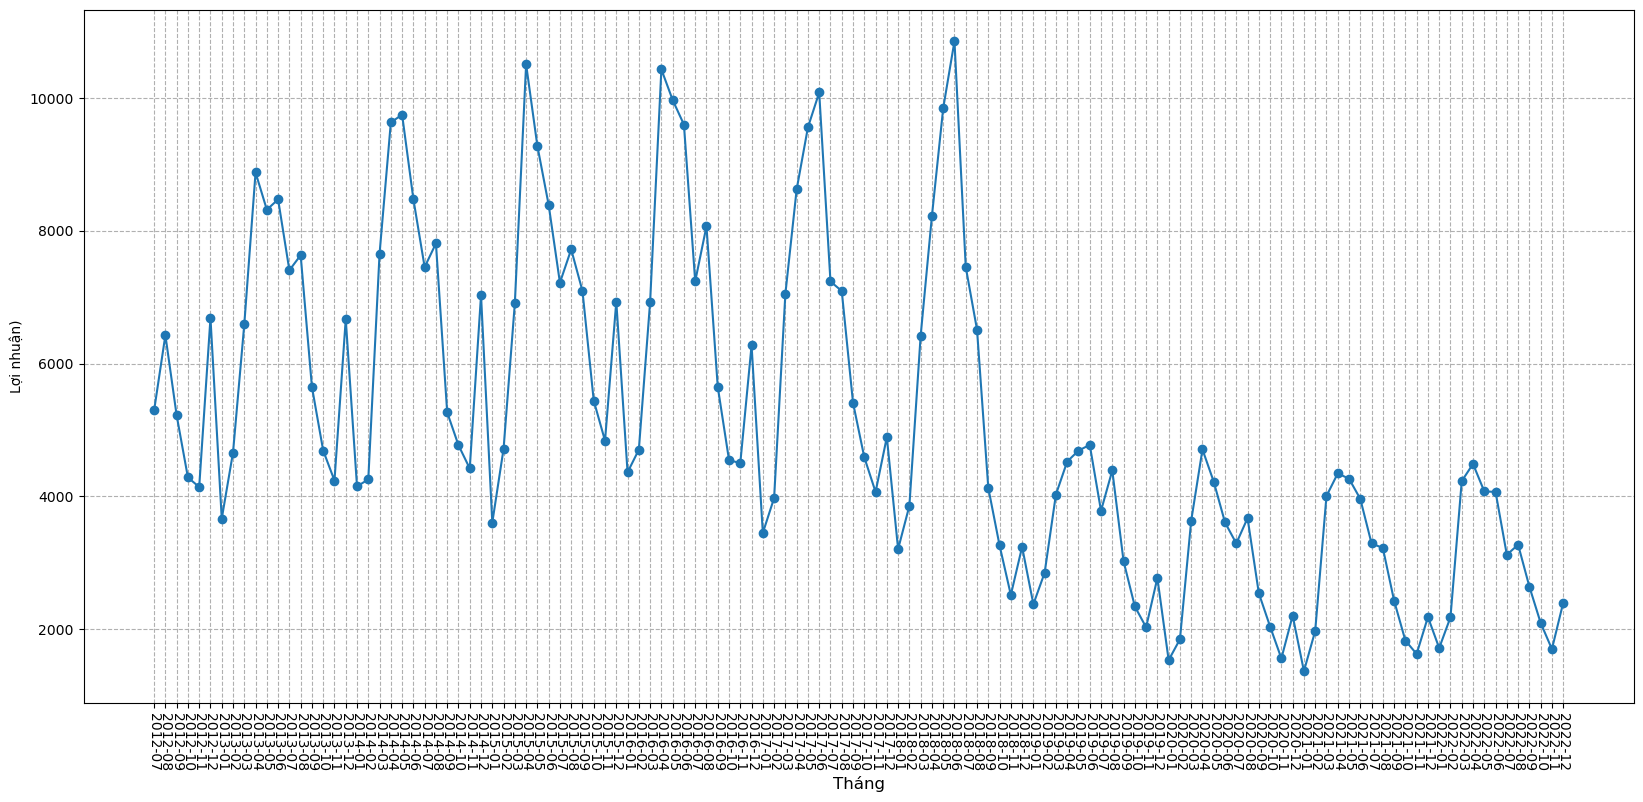

In [12]:
countOrder = dfOrder.groupby("yearMonth")["order_id"].count()

pig, ax =  plt.subplots(figsize=(20, 9))
ax.plot(
    countOrder.index,
    countOrder.values,
    marker = "o"
)
ax.set_ylabel('Lợi nhuận)')
ax.set_xlabel('Tháng', fontsize=12)
plt.xticks(rotation=270)
ax.grid(ls = "--")

plt.show()

## Chương trình khuyến mại

In [23]:
dfPromotions = pd.read_csv("Master/promotions.csv")
dfPromotions.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   promo_id             50 non-null     object 
 1   promo_name           50 non-null     object 
 2   promo_type           50 non-null     object 
 3   discount_value       50 non-null     float64
 4   start_date           50 non-null     object 
 5   end_date             50 non-null     object 
 6   applicable_category  10 non-null     object 
 7   promo_channel        50 non-null     object 
 8   stackable_flag       50 non-null     int64  
 9   min_order_value      50 non-null     int64  
dtypes: float64(1), int64(2), object(7)
memory usage: 4.0+ KB


In [25]:
dfPromotions["start_date"] = pd.to_datetime(dfPromotions["start_date"])
dfPromotions["end_date"] = pd.to_datetime(dfPromotions["end_date"])
dfPromotions['year'] = dfPromotions['start_date'].dt.year
dfPromotions['month'] = dfPromotions['start_date'].dt.month
dfPromotions['duration'] = (dfPromotions['end_date'] - dfPromotions['start_date']).dt.days
dfPromotions["yearMonth"] = dfPromotions["start_date"].dt.strftime("%Y-%m")


In [26]:
dfPromotions.head()

,promo_id,promo_name,promo_type,discount_value,start_date,end_date,applicable_category,promo_channel,stackable_flag,min_order_value,year,month,duration,yearMonth
0,PROMO-0001,Spring Sale 2013,percentage,12.0,2013-03-18,2013-04-17,NaN,email,1,0,2013,3,30,2013-03
1,PROMO-0002,Mid-Year Sale 2013,percentage,18.0,2013-06-23,2013-07-22,NaN,online,0,0,2013,6,29,2013-06
2,PROMO-0003,Fall Launch 2013,percentage,10.0,2013-08-30,2013-10-02,NaN,email,0,0,2013,8,33,2013-08
3,PROMO-0004,Year-End Sale 2013,percentage,20.0,2013-11-18,2014-01-02,NaN,all_channels,0,50000,2013,11,45,2013-11
4,PROMO-0005,Urban Blowout 2013,fixed,50.0,2013-07-30,2013-09-02,Streetwear,online,0,150000,2013,7,34,2013-07


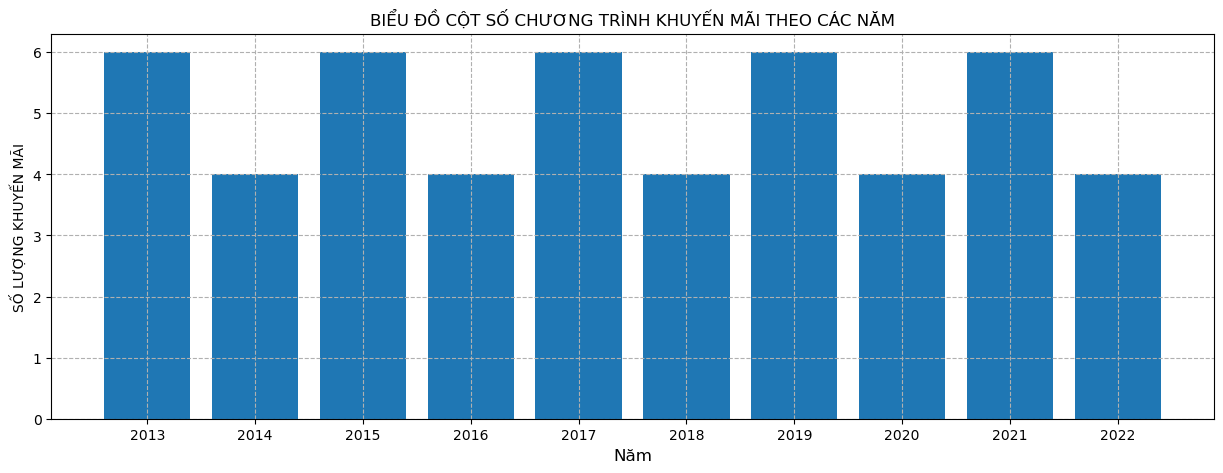

In [27]:
promo_per_year = dfPromotions.groupby(['year']).size()

pig, ax =  plt.subplots(figsize=(15, 5))
ax.bar(
    promo_per_year.index,
    promo_per_year.values
)
ax.set_title("BIỂU ĐỒ CỘT SỐ CHƯƠNG TRÌNH KHUYẾN MÃI THEO CÁC NĂM")
ax.set_ylabel('SỐ LƯỢNG KHUYẾN MÃI')
ax.set_xlabel('Năm', fontsize=12)
ax.grid(ls = "--")
ax.set_xticks(range(min(promo_per_year.index),max(promo_per_year.index)+1))
plt.show()

In [29]:
promo_per_month = dfPromotions.groupby(['yearMonth'])["duration"].mean().reset_index().sort_values(by = ['yearMonth'])

In [30]:
datyStart = min(dfPromotions["yearMonth"])
datyLast  = max(dfPromotions["yearMonth"])
dates = pd.date_range(start=datyStart, end=datyLast, freq='MS')
dates = [d.strftime('%Y-%m') for d in dates]
dates = pd.DataFrame(dates, columns=['yearMonth'])

In [31]:
promo_per_month = pd.merge(dates, promo_per_month, on='yearMonth', how='left').fillna(0).sort_values(by = ['yearMonth'])
promo_per_month

,yearMonth,duration
0,2013-01,29.0
1,2013-02,0.0
2,2013-03,30.0
3,2013-04,0.0
4,2013-05,0.0
...,...,...
114,2022-07,0.0
115,2022-08,31.0
116,2022-09,0.0
117,2022-10,0.0


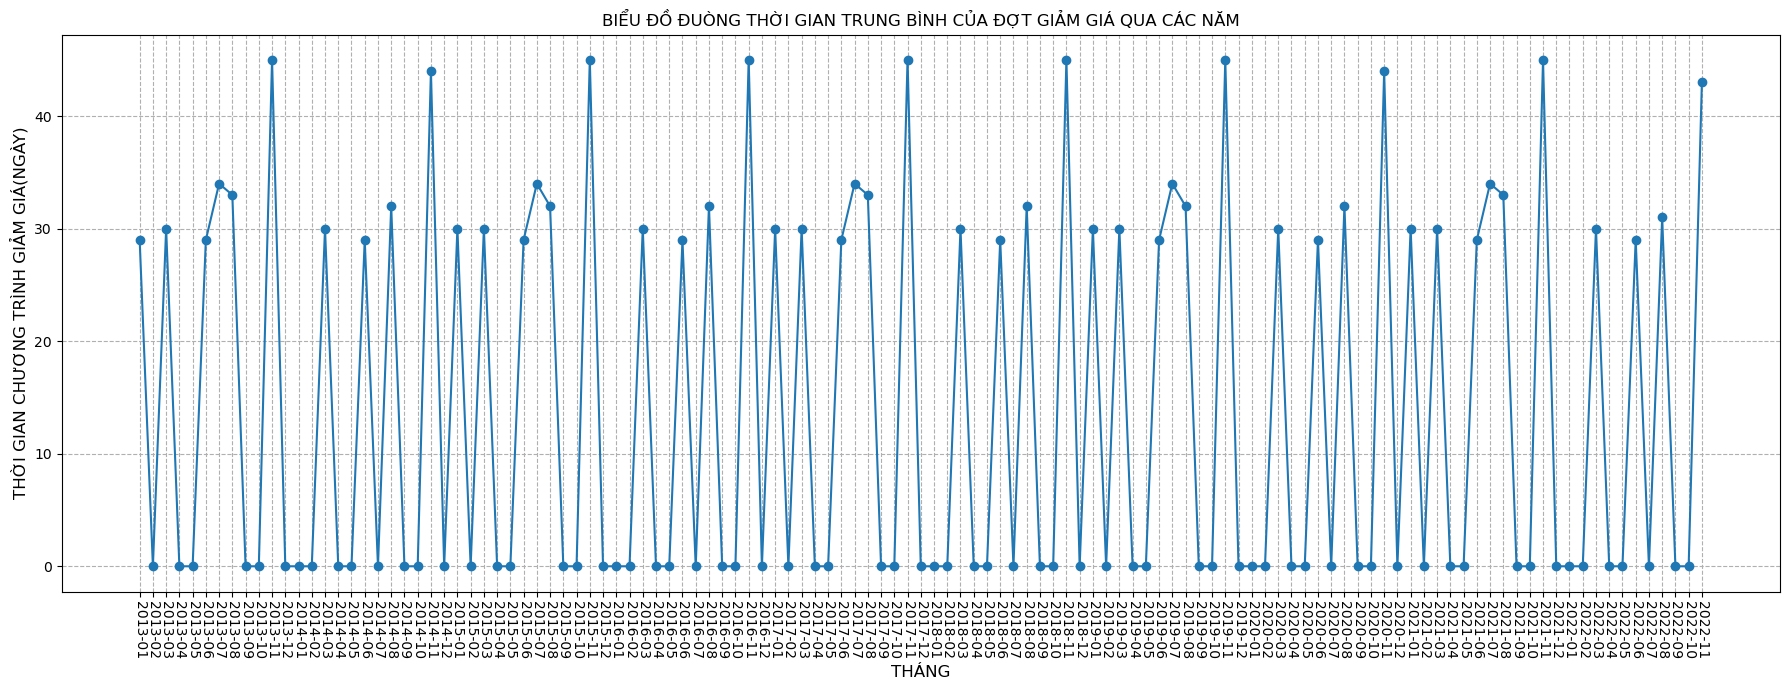

In [32]:
fig, ax = plt.subplots(figsize=(18, 7))
ax.plot(
    promo_per_month["yearMonth"].values,
    promo_per_month["duration"].values,
    marker = "o"
)
ax.grid(ls = "--")
ax.set_title("BIỂU ĐỒ ĐUÒNG THỜI GIAN TRUNG BÌNH CỦA ĐỢT GIẢM GIÁ QUA CÁC NĂM")
ax.set_ylabel('THỜI GIAN CHƯƠNG TRÌNH GIẢM GIÁ(NGÀY)', fontsize=12)
ax.set_xlabel('THÁNG', fontsize=12)
plt.xticks(rotation=270)
plt.tight_layout()

plt.show()

# Quản lý kho

In [34]:
dfWareHouse  = pd.read_csv("Operational/inventory.csv")
df_plot = dfWareHouse.copy()
dfWareHouse.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60247 entries, 0 to 60246
Data columns (total 17 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   snapshot_date      60247 non-null  object 
 1   product_id         60247 non-null  int64  
 2   stock_on_hand      60247 non-null  int64  
 3   units_received     60247 non-null  int64  
 4   units_sold         60247 non-null  int64  
 5   stockout_days      60247 non-null  int64  
 6   days_of_supply     60247 non-null  float64
 7   fill_rate          60247 non-null  float64
 8   stockout_flag      60247 non-null  int64  
 9   overstock_flag     60247 non-null  int64  
 10  reorder_flag       60247 non-null  int64  
 11  sell_through_rate  60247 non-null  float64
 12  product_name       60247 non-null  object 
 13  category           60247 non-null  object 
 14  segment            60247 non-null  object 
 15  year               60247 non-null  int64  
 16  month              602

In [35]:
dfWareHouse.describe()

,product_id,stock_on_hand,units_received,units_sold,stockout_days,days_of_supply,fill_rate,stockout_flag,overstock_flag,reorder_flag,sell_through_rate,year,month
count,60247.000000,60247.000000,60247.000000,60247.000000,60247.000000,60247.000000,60247.000000,60247.000000,60247.000000,60247.0,60247.000000,60247.000000,60247.000000
mean,1311.408468,189.298455,18.046807,15.417764,1.160639,912.677576,0.961312,0.673411,0.762561,0.0,0.152275,2017.222799,6.617292
std,673.051769,316.976124,34.080228,28.404379,1.624490,2587.624108,0.054156,0.468969,0.425517,0.0,0.139291,2.972353,3.385629
min,1.000000,3.000000,1.000000,1.000000,0.000000,5.200000,0.066700,0.000000,0.000000,0.0,0.000400,2012.000000,1.000000
25%,760.000000,15.000000,2.000000,2.000000,0.000000,96.000000,0.933300,0.000000,1.000000,0.0,0.042100,2015.000000,4.000000
50%,1223.000000,62.000000,6.000000,6.000000,1.000000,240.000000,0.966700,1.000000,1.000000,0.0,0.111100,2017.000000,7.000000
75%,1942.000000,210.000000,19.000000,16.000000,2.000000,683.100000,1.000000,1.000000,1.000000,0.0,0.238100,2020.000000,10.000000
max,2412.000000,2673.000000,817.000000,670.000000,28.000000,68100.000000,1.000000,1.000000,1.000000,0.0,0.853100,2022.000000,12.000000


In [36]:
monthly_trend = dfWareHouse.groupby(['year', 'month'])[['units_sold', 'units_received']].sum().reset_index()
monthly_trend.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 126 entries, 0 to 125
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   year            126 non-null    int64
 1   month           126 non-null    int64
 2   units_sold      126 non-null    int64
 3   units_received  126 non-null    int64
dtypes: int64(4)
memory usage: 4.1 KB


## Tổng quan về kho

In [38]:
monthly_trend['per'] = (monthly_trend['units_sold']/monthly_trend['units_received'])

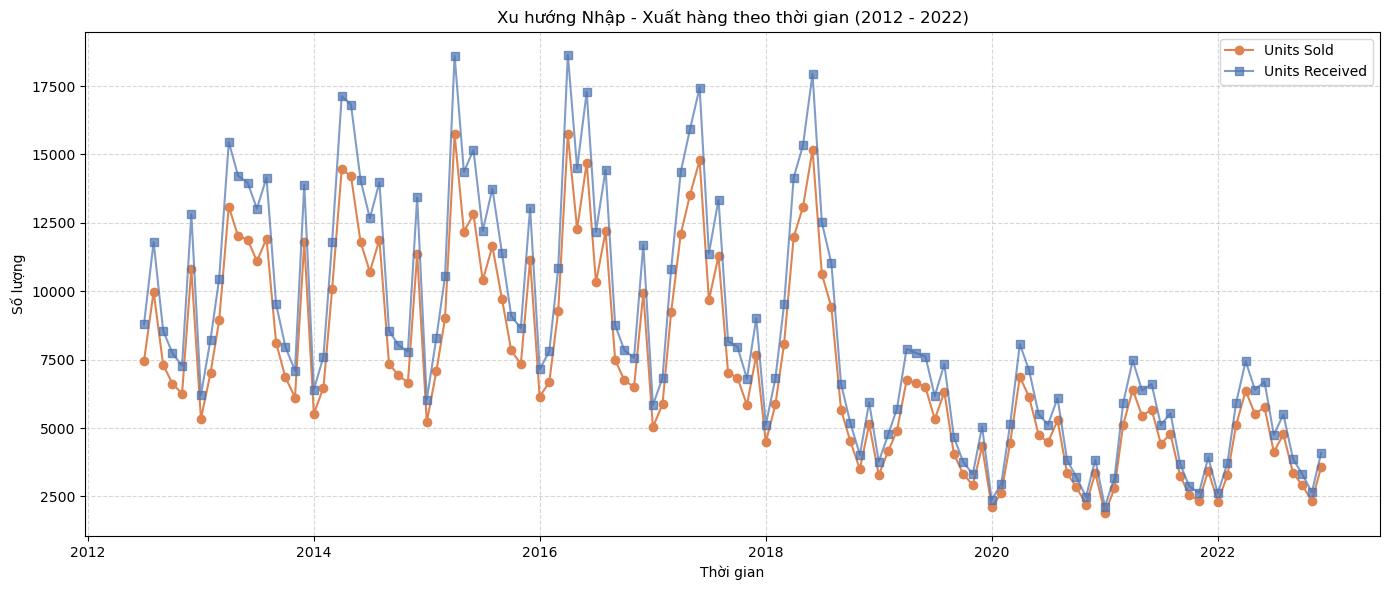

In [40]:
monthly_trend['date'] = pd.to_datetime(monthly_trend[['year', 'month']].assign(DAY=1))
monthly_trend = monthly_trend.sort_values('date')

# Tùy chỉnh Matplotlib line chart
plt.figure(figsize=(14, 6))
plt.plot(monthly_trend['date'], monthly_trend['units_sold'], label='Units Sold', marker='o', color='#DD8452')
plt.plot(monthly_trend['date'], monthly_trend['units_received'], label='Units Received', marker='s', color='#4C72B0', alpha=0.7)

plt.title('Xu hướng Nhập - Xuất hàng theo thời gian (2012 - 2022)')
plt.xlabel('Thời gian')
plt.ylabel('Số lượng')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

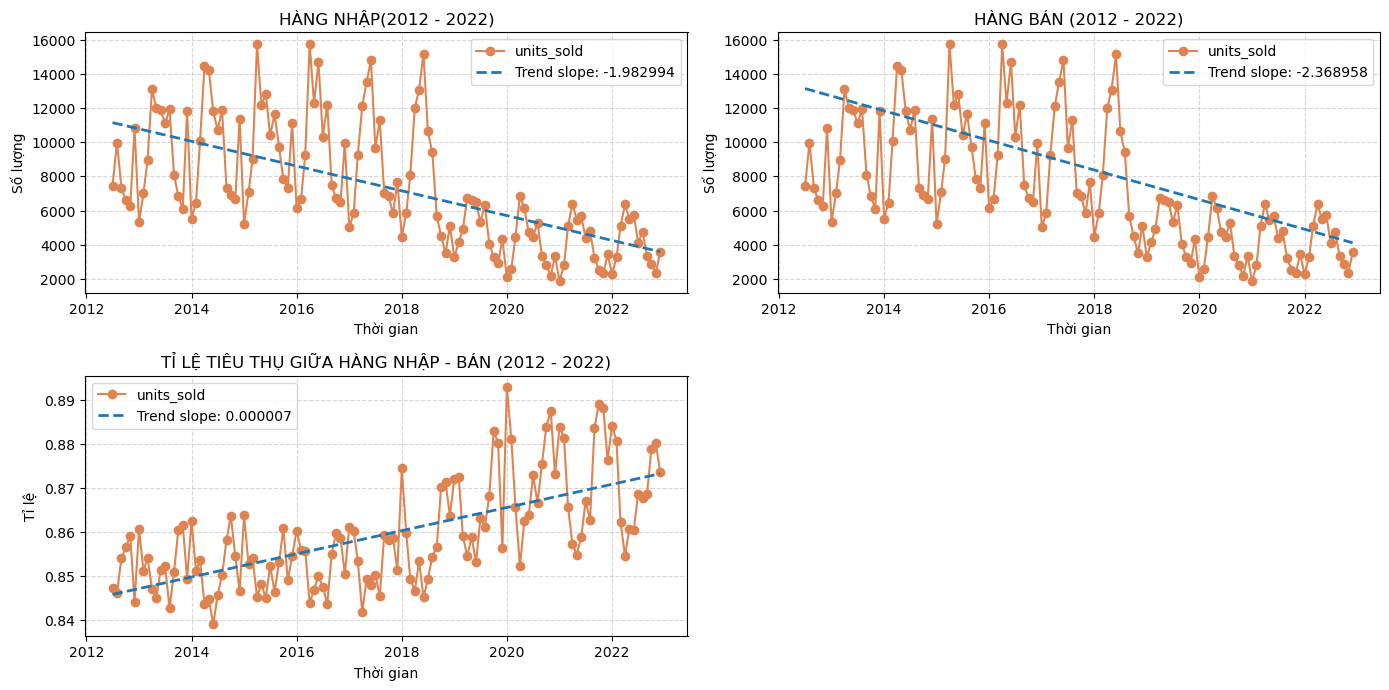

In [62]:
x = monthly_trend['date'].map(pd.Timestamp.toordinal)
y1 = monthly_trend['units_sold']


coeffs1 = np.polyfit(x, y1, 1)
trend1 = np.poly1d(coeffs1)
trend_values1 = trend1(x)


plt.figure(figsize=(14, 10))


plt.subplot(3,2,1)
plt.plot(monthly_trend['date'], monthly_trend['units_sold'], label='units_sold', marker='o', color='#DD8452')
plt.plot(
    monthly_trend['date'],
    trend_values1,
    linestyle='--',
    linewidth=2,
    label=f'Trend slope: {coeffs1[0]:.6f}'
)


plt.title('HÀNG NHẬP(2012 - 2022)')
plt.xlabel('Thời gian')
plt.ylabel('Số lượng')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)



plt.subplot(3,2,2)
y2 = monthly_trend['units_received']


coeffs2 = np.polyfit(x, y2, 1)
trend2 = np.poly1d(coeffs2)
trend_values2 = trend2(x)

plt.plot(monthly_trend['date'], monthly_trend['units_sold'], label='units_sold', marker='o', color='#DD8452')
plt.plot(
    monthly_trend['date'],
    trend_values2,
    linestyle='--',
    linewidth=2,
    label=f'Trend slope: {coeffs2[0]:.6f}'
)
plt.title('HÀNG BÁN (2012 - 2022)')
plt.xlabel('Thời gian')
plt.ylabel('Số lượng')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)


plt.subplot(3,2,3)
y3 = monthly_trend['per']


coeffs3 = np.polyfit(x, y3, 1)
trend3 = np.poly1d(coeffs3)
trend_values3 = trend3(x)

plt.plot(monthly_trend['date'], monthly_trend['per'], label='units_sold', marker='o', color='#DD8452')
plt.plot(
    monthly_trend['date'],
    trend_values3,
    linestyle='--',
    linewidth=2,
    label=f'Trend slope: {coeffs3[0]:.6f}'
)

plt.title('TỈ LỆ TIÊU THỤ GIỮA HÀNG NHẬP - BÁN (2012 - 2022)')
plt.xlabel('Thời gian')
plt.ylabel('Tỉ lệ')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)


plt.tight_layout()
plt.show()

In [64]:
monthly_trend
pd.pivot_table(monthly_trend, values='per', index=['year'], columns=['month'], aggfunc='sum').fillna(0)

month,1,2,3,4,5,6,7,8,9,10,11,12
year,,,,,,,,,,,,
2012,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.847090,0.846089,0.853952,0.856441,0.859126,0.844052
2013,0.860574,0.851087,0.854111,0.847050,0.844851,0.851353,0.852239,0.842566,0.850771,0.860369,0.861612,0.849338
2014,0.862430,0.851019,0.853485,0.843558,0.844755,0.838891,0.845528,0.850043,0.858144,0.863653,0.854429,0.846463
2015,0.863719,0.852647,0.853973,0.845117,0.848099,0.844926,0.852213,0.846372,0.853060,0.860785,0.848930,0.854515
2016,0.860283,0.855806,0.855707,0.843703,0.846801,0.849936,0.847487,0.843555,0.854907,0.859694,0.858654,0.850329
2017,0.861130,0.860094,0.853395,0.841662,0.849124,0.847839,0.850149,0.845382,0.859277,0.858074,0.858529,0.851198
2018,0.874488,0.859762,0.849233,0.846534,0.853229,0.845040,0.849269,0.854303,0.856647,0.870160,0.871361,0.863682
2019,0.872115,0.872563,0.859044,0.854446,0.858729,0.853015,0.863120,0.861176,0.868212,0.882979,0.880290,0.856295
2020,0.892917,0.881242,0.865593,0.852095,0.862447,0.863719,0.872926,0.866568,0.875459,0.884004,0.887545,0.873115


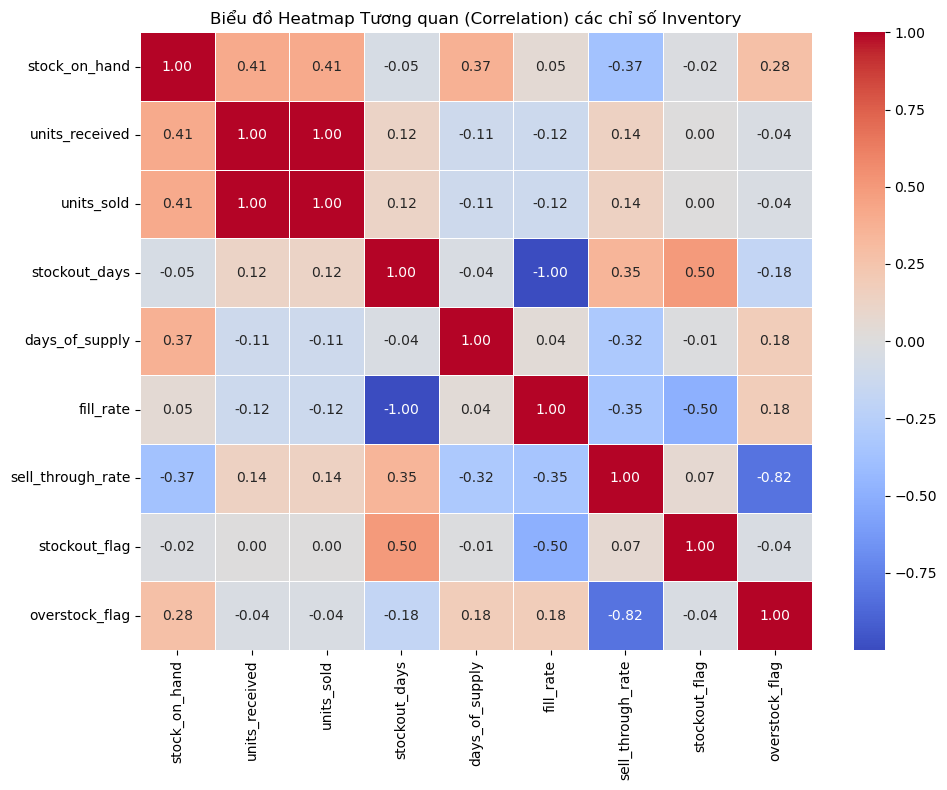

In [26]:
import seaborn as sns
plt.figure(figsize=(10, 8))

# Lọc các cột số (numeric) cần phân tích
corr_cols = ['stock_on_hand', 'units_received', 'units_sold', 'stockout_days', 'days_of_supply', 'fill_rate', 'sell_through_rate','stockout_flag', 'overstock_flag']
corr = dfWareHouse[corr_cols].corr()

# Tùy chỉnh Seaborn heatmap
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Biểu đồ Heatmap Tương quan (Correlation) các chỉ số Inventory')
plt.tight_layout()
plt.show()

**Phân tích này giúp xác định cách các chỉ số chuỗi cung ứng tác động qua lại lẫn nhau:**
- Tỷ lệ Bán ra (Sell-through rate): Chỉ số này có tương quan âm (-0.37) với stock_on_hand và days_of_supply. Nghĩa là khi lượng hàng tồn hoặc số ngày lưu kho tăng lên, tốc độ bán ra thực tế lại có xu hướng giảm. Đây là một điểm nghẽn (bottleneck) đáng chú ý, cho thấy dấu hiệu đọng vốn do overstock và là một chủ đề rất tốt để đưa ra thảo luận trong các buổi brainstorming sắp tới cùng team.

## Tình trạng thiếu hàng

In [66]:
# Tình hình thiếu hàng ở từng danh mục sản phẩm
dfstockout_flag = dfWareHouse.groupby(["year","category"])["stockout_flag"].mean().reset_index().sort_values(by = 'year', ascending=False)
pd.pivot_table(dfstockout_flag, values='stockout_flag', index=['category'], columns=['year'], aggfunc='sum')

year,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022
category,,,,,,,,,,,
Casual,0.594059,0.678392,0.673171,0.623894,0.693277,0.681818,0.694301,0.630705,0.694382,0.625755,0.669565
GenZ,0.728972,0.674074,0.721003,0.713896,0.673317,0.708134,0.675214,0.664825,0.672101,0.669408,0.674718
Outdoor,0.665650,0.679263,0.677638,0.679642,0.685651,0.671733,0.652983,0.670687,0.670850,0.669714,0.678851
Streetwear,0.696362,0.678284,0.670608,0.670828,0.673503,0.677961,0.667089,0.675508,0.660422,0.688439,0.657885


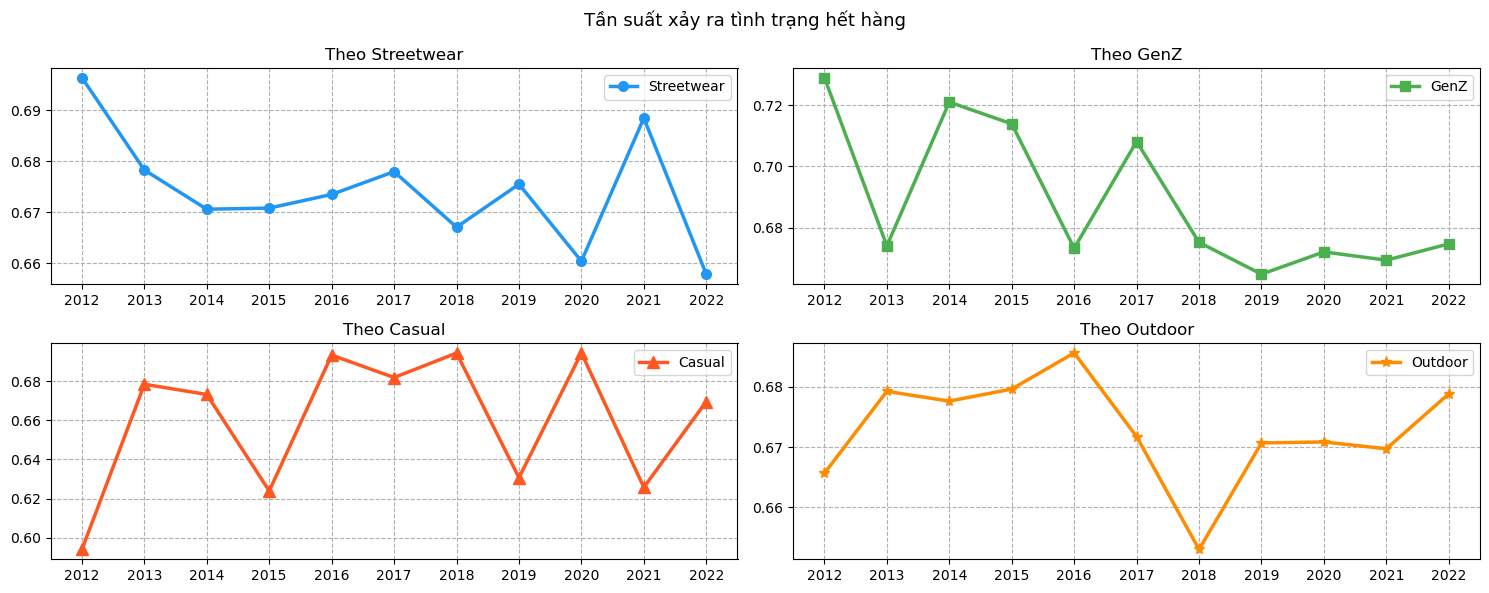

In [68]:
fig, ax = plt.subplots(2, 2, figsize=(15, 6))

fig.suptitle('Tần suất xảy ra tình trạng hết hàng', fontsize=13)

ax[0,0].plot(dfstockout_flag['year'].unique(),
        dfstockout_flag[dfstockout_flag['category'] == "Streetwear"]["stockout_flag"],
        color='#2196F3',
        linewidth=2.5,
        marker='o',
        markersize=7,
        label='Streetwear')
ax[0,0].set_xticks(range(min(dfstockout_flag['year']),max(dfstockout_flag['year'])+1))
ax[0,0].grid(ls = "--")
ax[0,0].set_title("Theo Streetwear")
ax[0,0].legend()


# Bieu do 2
# plt.subplot(2,2,2)
ax[0,1].plot(dfstockout_flag['year'].unique(),
        dfstockout_flag[dfstockout_flag['category'] == "GenZ"]["stockout_flag"],
        color='#4CAF50',
        linewidth=2.5,
        marker='s',
        markersize=7,
        label='GenZ')
ax[0,1].set_xticks(range(min(dfstockout_flag['year']),max(dfstockout_flag['year'])+1))
ax[0,1].grid(ls = "--")
ax[0,1].set_title("Theo GenZ")
ax[0,1].legend()


# Bieu do 1
# plt.subplot(2,2,3)
ax[1,0].plot(dfstockout_flag['year'].unique(),
        dfstockout_flag[dfstockout_flag['category'] == "Casual"]["stockout_flag"],
        color='#FF5722',
        linewidth=2.5,
        marker='^',
        markersize=8,
        label='Casual')
ax[1,0].set_xticks(range(min(dfstockout_flag['year']),max(dfstockout_flag['year'])+1))
ax[1,0].grid(ls = "--")
ax[1,0].set_title("Theo Casual")
ax[1,0].legend()


# Bieu do 1
# plt.subplot(2,2,4)
ax[1,1].plot(dfstockout_flag['year'].unique(),
        dfstockout_flag[dfstockout_flag['category'] == "Outdoor"]["stockout_flag"],
        color='darkorange',
        linewidth=2.5,
        marker='*',
        markersize=8,
        label='Outdoor')
ax[1,1].set_xticks(range(min(dfstockout_flag['year']),max(dfstockout_flag['year'])+1))
ax[1,1].grid(ls = "--")
ax[1,1].set_title("Theo Outdoor")
ax[1,1].legend()


plt.tight_layout()
plt.show()

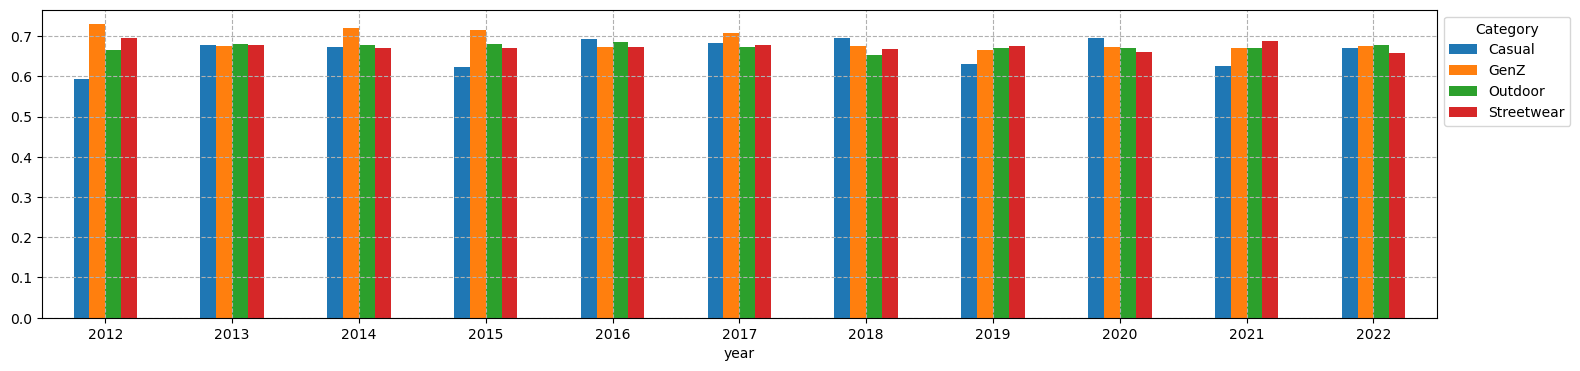

In [30]:
plt.rcParams['figure.figsize'] = (18, 4)
pd.pivot_table(dfstockout_flag, values='stockout_flag', index=['year'], columns=['category'], aggfunc='sum').plot(kind = 'bar', stacked = False)
plt.xticks(rotation = 0)
plt.grid(ls = "--")
plt.legend(title='Category', loc='upper left', bbox_to_anchor=(1.0, 1.0))
plt.show()

In [76]:
# Số ngày hết hàng trong tháng của mỗi sản phẩm
dfstockout_days = dfWareHouse.groupby(["year","category"])["stockout_days"].mean().sort_values(ascending=False).reset_index().sort_values(by = 'year', ascending=False)
pd.pivot_table(dfstockout_days, values='stockout_days', index=['category'], columns=['year'], aggfunc='sum')

year,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022
category,,,,,,,,,,,
Casual,0.930693,1.010050,0.990244,0.977876,1.033613,1.469697,1.764249,0.981328,1.062921,1.062374,1.095652
GenZ,1.074766,1.429630,1.297806,1.329700,1.059850,1.110048,1.273504,1.071823,0.990942,1.098684,1.099839
Outdoor,1.421748,1.358054,1.143372,1.167338,1.059161,1.115502,0.996181,1.009963,0.997718,1.068860,1.076371
Streetwear,1.418708,1.196381,1.250246,1.229632,1.312603,1.226525,1.099462,1.128832,1.057221,1.206078,1.102711


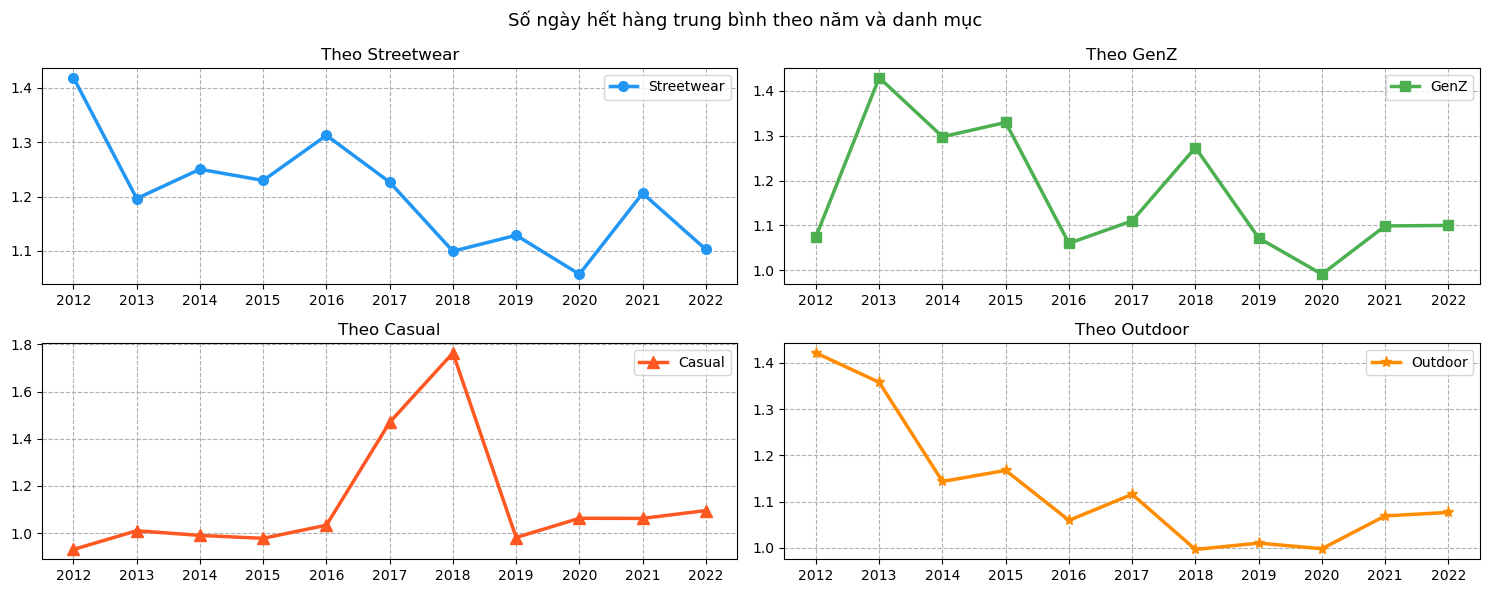

In [80]:
fig, ax = plt.subplots(2, 2, figsize=(15, 6))

fig.suptitle('Số ngày hết hàng trung bình theo năm và danh mục', fontsize=13)

ax[0,0].plot(dfstockout_days['year'].unique(),
        dfstockout_days[dfstockout_days['category'] == "Streetwear"]["stockout_days"],
        color='#2196F3',
        linewidth=2.5,
        marker='o',
        markersize=7,
        label='Streetwear')
ax[0,0].set_xticks(range(min(dfstockout_days['year']),max(dfstockout_days['year'])+1))
ax[0,0].grid(ls = "--")
ax[0,0].set_title("Theo Streetwear")
ax[0,0].legend()


# Bieu do 2
# plt.subplot(2,2,2)
ax[0,1].plot(dfstockout_days['year'].unique(),
        dfstockout_days[dfstockout_days['category'] == "GenZ"]["stockout_days"],
        color='#4CAF50',
        linewidth=2.5,
        marker='s',
        markersize=7,
        label='GenZ')
ax[0,1].set_xticks(range(min(dfstockout_days['year']),max(dfstockout_days['year'])+1))
ax[0,1].grid(ls = "--")
ax[0,1].set_title("Theo GenZ")
ax[0,1].legend()


# Bieu do 1
# plt.subplot(2,2,3)
ax[1,0].plot(dfstockout_days['year'].unique(),
        dfstockout_days[dfstockout_days['category'] == "Casual"]["stockout_days"],
        color='#FF5722',
        linewidth=2.5,
        marker='^',
        markersize=8,
        label='Casual')
ax[1,0].set_xticks(range(min(dfstockout_days['year']),max(dfstockout_days['year'])+1))
ax[1,0].grid(ls = "--")
ax[1,0].set_title("Theo Casual")
ax[1,0].legend()


# Bieu do 1
# plt.subplot(2,2,4)
ax[1,1].plot(dfstockout_days['year'].unique(),
        dfstockout_days[dfstockout_days['category'] == "Outdoor"]["stockout_days"],
        color='darkorange',
        linewidth=2.5,
        marker='*',
        markersize=8,
        label='Outdoor')
ax[1,1].set_xticks(range(min(dfstockout_days['year']),max(dfstockout_days['year'])+1))
ax[1,1].grid(ls = "--")
ax[1,1].set_title("Theo Outdoor")
ax[1,1].legend()


plt.tight_layout()
plt.show()

## Thừa hàng

In [88]:
# Hàng hóa gặp tình trạng vượt quá mức cần thiết
dfMeanoverstock_flag = dfWareHouse.groupby(["year","category"])["overstock_flag"].mean().reset_index().sort_values(by = 'year', ascending=False)
pd.pivot_table(dfMeanoverstock_flag, values='overstock_flag', index=['category'], columns=['year'], aggfunc='sum')

year,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022
category,,,,,,,,,,,
Casual,0.623762,0.703518,0.814634,0.796460,0.827731,0.768939,0.686528,0.705394,0.759551,0.672032,0.686957
GenZ,0.785047,0.666667,0.658307,0.675749,0.680798,0.758373,0.694444,0.732965,0.746377,0.722039,0.743961
Outdoor,0.464431,0.670761,0.797565,0.825056,0.819868,0.833695,0.853461,0.839539,0.867085,0.833638,0.825718
Streetwear,0.624350,0.650469,0.702135,0.756570,0.756533,0.758632,0.780171,0.837754,0.815736,0.748865,0.743414


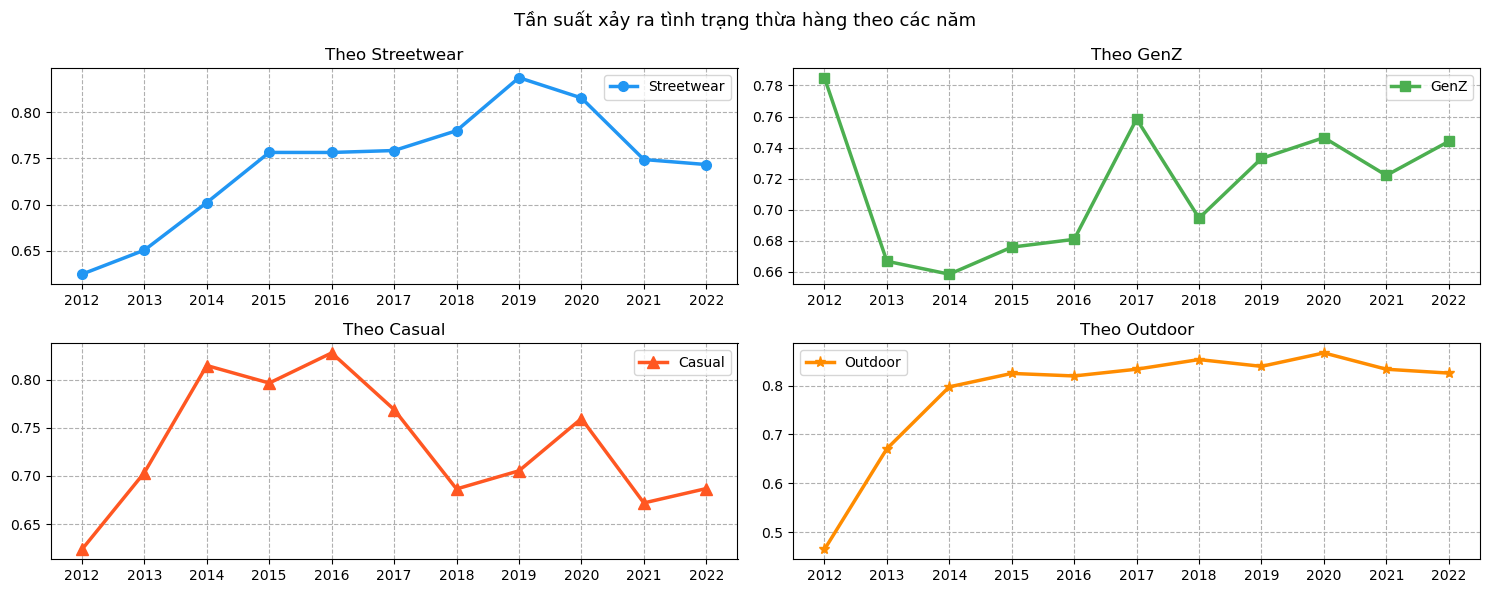

In [90]:
fig, ax = plt.subplots(2, 2, figsize=(15, 6))

fig.suptitle('Tần suất xảy ra tình trạng thừa hàng theo các năm', fontsize=13)

ax[0,0].plot(dfMeanoverstock_flag['year'].unique(),
        dfMeanoverstock_flag[dfMeanoverstock_flag['category'] == "Streetwear"]["overstock_flag"],
        color='#2196F3',
        linewidth=2.5,
        marker='o',
        markersize=7,
        label='Streetwear')
ax[0,0].set_xticks(range(min(dfMeanoverstock_flag['year']),max(dfMeanoverstock_flag['year'])+1))
ax[0,0].grid(ls = "--")
ax[0,0].set_title("Theo Streetwear")
ax[0,0].legend()


# Bieu do 2
# plt.subplot(2,2,2)
ax[0,1].plot(dfMeanoverstock_flag['year'].unique(),
        dfMeanoverstock_flag[dfMeanoverstock_flag['category'] == "GenZ"]["overstock_flag"],
        color='#4CAF50',
        linewidth=2.5,
        marker='s',
        markersize=7,
        label='GenZ')
ax[0,1].set_xticks(range(min(dfMeanoverstock_flag['year']),max(dfMeanoverstock_flag['year'])+1))
ax[0,1].grid(ls = "--")
ax[0,1].set_title("Theo GenZ")
ax[0,1].legend()


# Bieu do 1
# plt.subplot(2,2,3)
ax[1,0].plot(dfMeanoverstock_flag['year'].unique(),
        dfMeanoverstock_flag[dfMeanoverstock_flag['category'] == "Casual"]["overstock_flag"],
        color='#FF5722',
        linewidth=2.5,
        marker='^',
        markersize=8,
        label='Casual')
ax[1,0].set_xticks(range(min(dfMeanoverstock_flag['year']),max(dfMeanoverstock_flag['year'])+1))
ax[1,0].grid(ls = "--")
ax[1,0].set_title("Theo Casual")
ax[1,0].legend()


# Bieu do 1
# plt.subplot(2,2,4)
ax[1,1].plot(dfMeanoverstock_flag['year'].unique(),
        dfMeanoverstock_flag[dfMeanoverstock_flag['category'] == "Outdoor"]["overstock_flag"],
        color='darkorange',
        linewidth=2.5,
        marker='*',
        markersize=8,
        label='Outdoor')
ax[1,1].set_xticks(range(min(dfMeanoverstock_flag['year']),max(dfMeanoverstock_flag['year'])+1))
ax[1,1].grid(ls = "--")
ax[1,1].set_title("Theo Outdoor")
ax[1,1].legend()


plt.tight_layout()
plt.show()

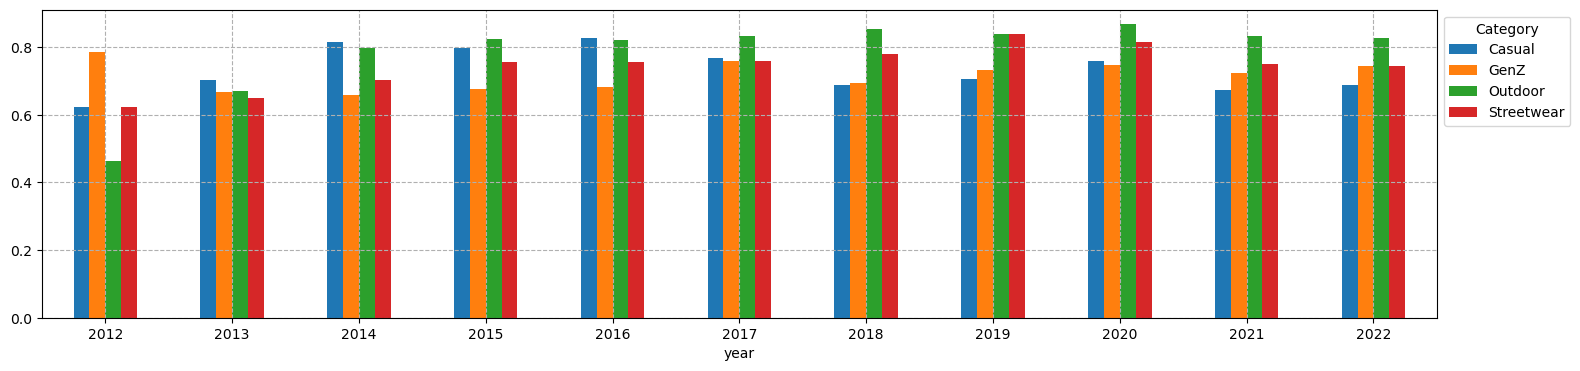

In [92]:
plt.rcParams['figure.figsize'] = (18, 4)
pd.pivot_table(dfMeanoverstock_flag, values='overstock_flag', index=['year'], columns=['category'], aggfunc='sum').plot(kind = 'bar', stacked = False)
plt.xticks(rotation = 0)
plt.grid(ls = "--")
plt.legend(title='Category', loc='upper left', bbox_to_anchor=(1.0, 1.0))
plt.show()

In [38]:
# Loại hàng cần tái đặt hàng sớm nhiều nhất
dfCategory_Reorder_Flag = dfWareHouse.groupby(["year","category"])["reorder_flag"].sum().sort_values(ascending=False).reset_index()
pd.pivot_table(dfCategory_Reorder_Flag, values='reorder_flag', index=['category'], columns=['year'], aggfunc='sum')

year,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022
category,,,,,,,,,,,
Casual,0,0,0,0,0,0,0,0,0,0,0
GenZ,0,0,0,0,0,0,0,0,0,0,0
Outdoor,0,0,0,0,0,0,0,0,0,0,0
Streetwear,0,0,0,0,0,0,0,0,0,0,0


In [39]:
# Loại hàng cần tái đặt hàng sớm nhiều nhất
test = dfWareHouse.groupby(['year','category'])["days_of_supply"].mean().sort_values(ascending=False).reset_index()
pd.pivot_table(test, values='days_of_supply', index=['category'], columns=['year'], aggfunc='sum')

year,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022
category,,,,,,,,,,,
Casual,158.664356,170.611558,271.544878,311.464159,319.167227,299.568182,431.429534,565.292739,689.853933,551.223139,559.377391
GenZ,267.558879,269.166296,328.844828,372.755858,629.714464,651.446172,654.077991,810.180110,856.273370,909.573849,1159.712399
Outdoor,118.384553,224.290316,533.299820,911.060850,904.028609,775.286062,1127.583055,1683.487310,1860.290645,1804.078245,1998.208681
Streetwear,184.047587,239.030228,430.917931,612.363042,628.172048,942.783866,841.944536,1176.132621,1353.487500,1391.260286,1730.287514


## SỐ LƯỢNG ĐƠN HÀNG

In [41]:
dfOrder_item = pd.read_csv("Transaction/order_items.csv")
dfOrder = pd.read_csv("Transaction/orders.csv")
dfOrder_item.info()

C:\Users\DANG DUY\AppData\Local\Temp\ipykernel_14360\2142049474.py:1: DtypeWarning: Columns (6) have mixed types. Specify dtype option on import or set low_memory=False.
  dfOrder_item = pd.read_csv("Transaction/order_items.csv")


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 714669 entries, 0 to 714668
Data columns (total 7 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   order_id         714669 non-null  int64  
 1   product_id       714669 non-null  int64  
 2   quantity         714669 non-null  int64  
 3   unit_price       714669 non-null  float64
 4   discount_amount  714669 non-null  float64
 5   promo_id         276316 non-null  object 
 6   promo_id_2       206 non-null     object 
dtypes: float64(2), int64(3), object(2)
memory usage: 38.2+ MB


In [42]:
dfOrder.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 646945 entries, 0 to 646944
Data columns (total 8 columns):
 #   Column          Non-Null Count   Dtype 
---  ------          --------------   ----- 
 0   order_id        646945 non-null  int64 
 1   order_date      646945 non-null  object
 2   customer_id     646945 non-null  int64 
 3   zip             646945 non-null  int64 
 4   order_status    646945 non-null  object
 5   payment_method  646945 non-null  object
 6   device_type     646945 non-null  object
 7   order_source    646945 non-null  object
dtypes: int64(3), object(5)
memory usage: 39.5+ MB


In [43]:
# Số lượng đơn hàng
dfOrder["order_date"] = pd.to_datetime(dfOrder["order_date"])
dfOrder["yearMonth"] = dfOrder["order_date"].dt.strftime("%Y-%m")
dfOrder["year"] = dfOrder["order_date"].dt.year
dfOrder["month"] = dfOrder["order_date"].dt.month


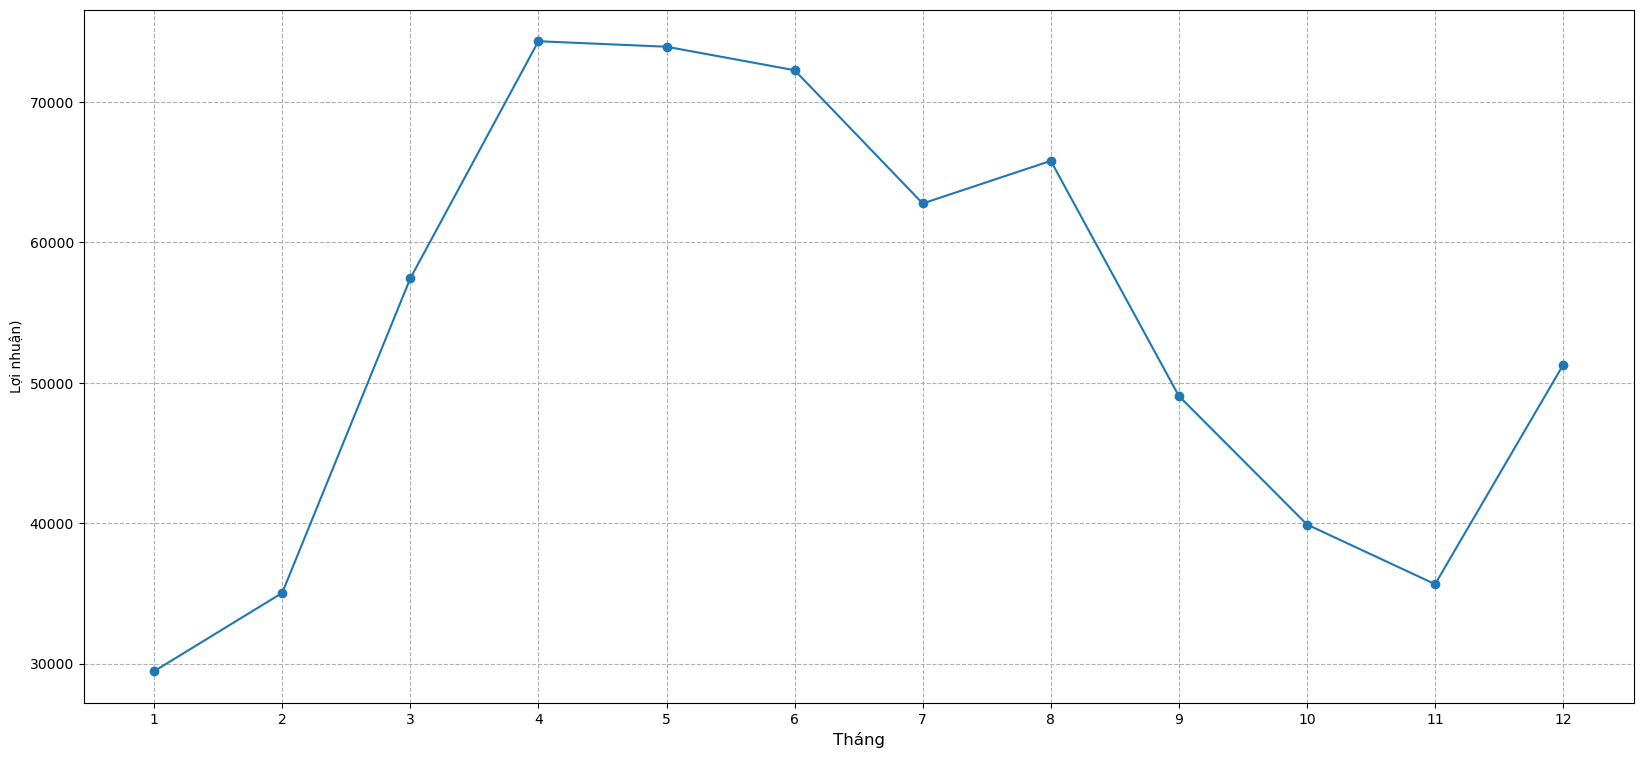

In [44]:
pig, ax =  plt.subplots(figsize=(20, 9))
ax.plot(
    dfOrder.groupby("month")["order_id"].count().index,
    dfOrder.groupby("month")["order_id"].count().values,
    marker = 'o'
)
ax.set_ylabel('Lợi nhuận)')
ax.set_xlabel('Tháng', fontsize=12)
# plt.xticks(rotation=270)
plt.xticks(range(1,13))  
ax.grid(ls = "--")

plt.show()

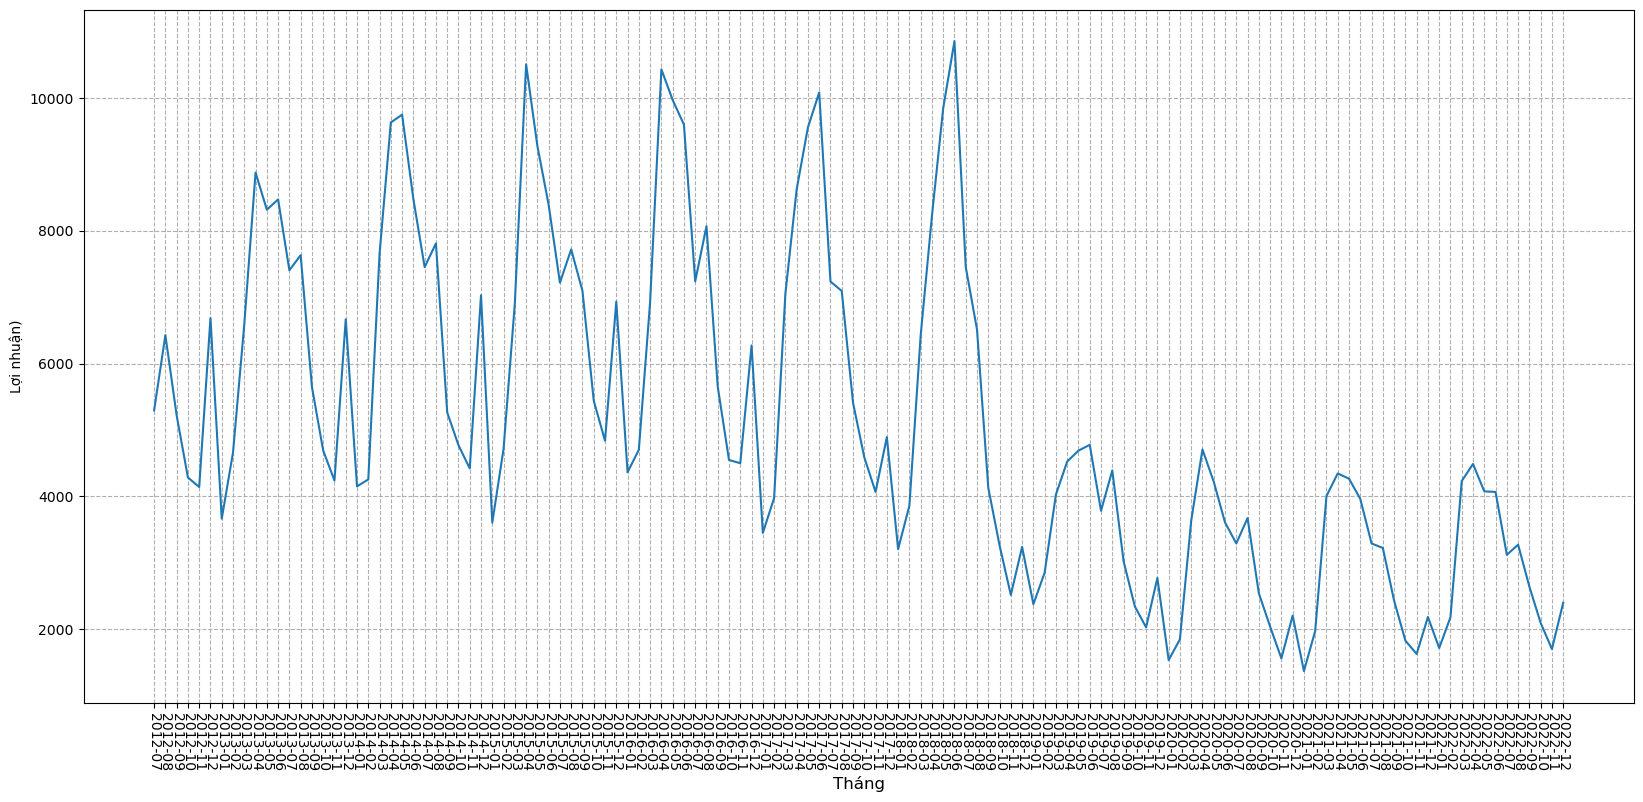

In [45]:
countOrder = dfOrder.groupby("yearMonth")["order_id"].count()

pig, ax =  plt.subplots(figsize=(20, 9))
ax.plot(
    countOrder.index,
    countOrder.values
)
ax.set_ylabel('Lợi nhuận)')
ax.set_xlabel('Tháng', fontsize=12)
plt.xticks(rotation=270)
ax.grid(ls = "--")

plt.show()

In [46]:
orderFull = pd.merge(dfOrder, dfOrder_item, on='order_id', how='left').sort_values(by = ['yearMonth'])

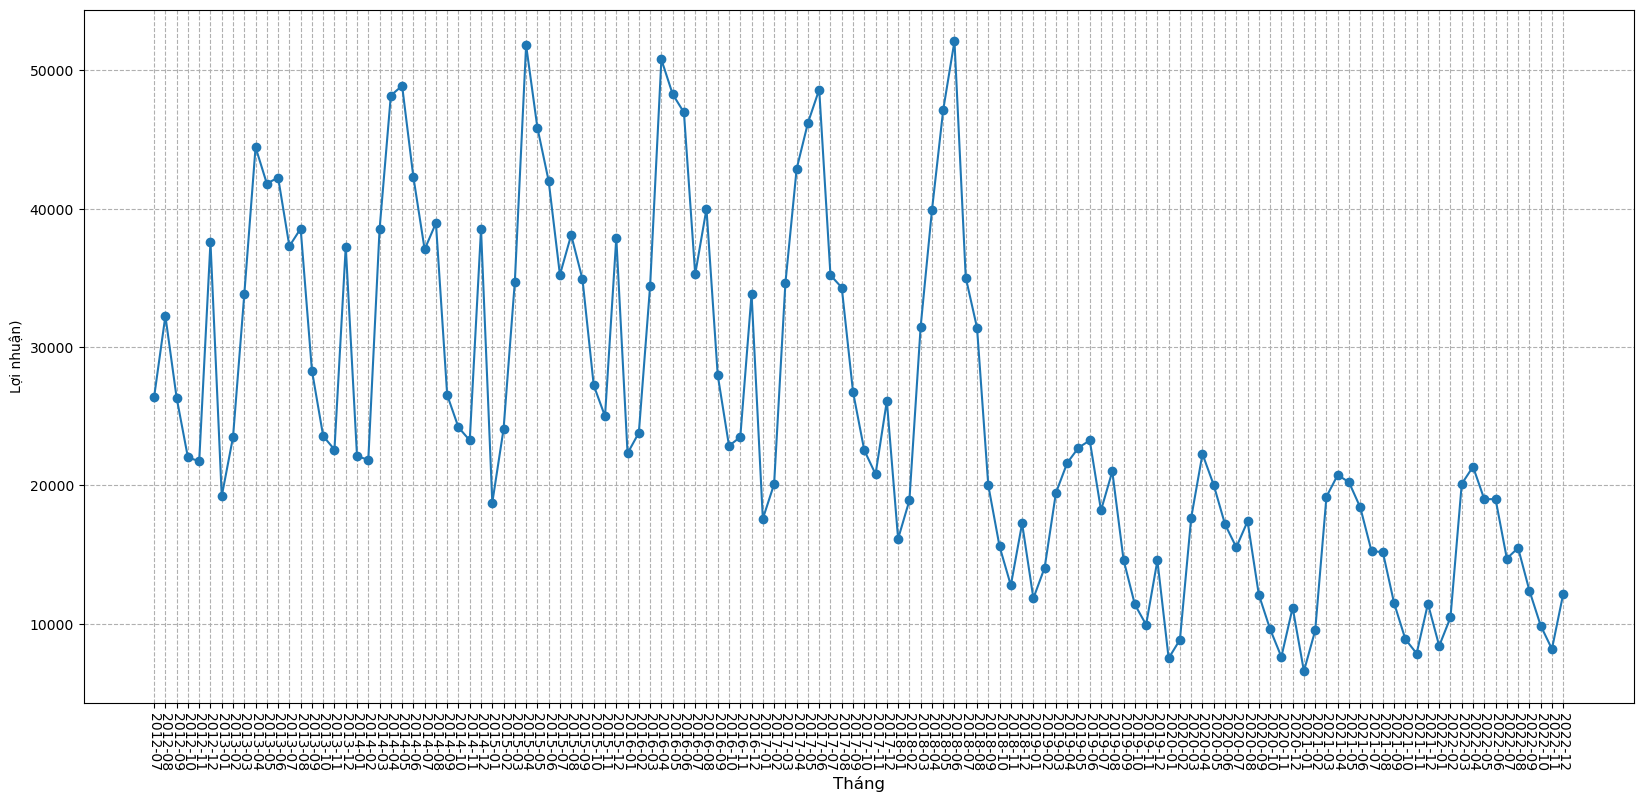

In [47]:
countQuantity = orderFull.groupby("yearMonth")["quantity"].sum()

pig, ax =  plt.subplots(figsize=(20, 9))
ax.plot(
    countQuantity.index,
    countQuantity.values,
    marker = "o"
)
ax.set_ylabel('Lợi nhuận)')
ax.set_xlabel('Tháng', fontsize=12)
plt.xticks(rotation=270)
ax.grid(ls = "--")

plt.show()

**Nhận xét**

- Tính mùa vụ cực cao sẵn sàng bán lỗ trong 1 khoảng thời gian

# SẢN PHẨM + KHUYẾN MẠI + ĐƠN HÀNG + TRẢ HÀNG + NHẬN XÉT

In [96]:
dfProduct = pd.read_csv("Master/products.csv")

In [98]:
dfProduct.sort_values(by = 'product_id')

,product_id,product_name,category,segment,size,color,price,cogs
1320,1,DragonWear MA-01,Casual,All-weather,M,black,4945.500000,2732.883300
1321,2,DragonWear MA-02,Casual,All-weather,L,orange,39.062877,22.660233
1322,3,DragonWear MA-03,Casual,All-weather,XL,blue,10831.377188,10289.808329
1323,4,DragonWear MA-04,Casual,All-weather,S,white,9610.756522,5604.032128
1324,5,DragonWear MA-05,Casual,All-weather,M,purple,8946.000000,8498.700000
...,...,...,...,...,...,...,...,...
1660,2408,VietMotion YY-17,GenZ,Trendy,S,pink,50.570570,28.534422
1661,2409,VietMotion YY-18,GenZ,Trendy,M,yellow,16.387260,9.830534
1662,2410,VietMotion YY-19,GenZ,Trendy,L,red,1234.170000,1020.041505
1663,2411,VietMotion YY-20,GenZ,Trendy,XL,black,20.628974,12.621128


## KHÁCH HÀNG VÀ VỊ TRÍ ĐỊA LÝ